In [1]:
import numpy as np
from scipy.stats import norm, t
import matplotlib.pyplot as plt

# Regressione lineare -- 28-01-25

In [2]:
x = np.array([1213, 1518, 1550, 1215, 2120, 2207])
y = np.array([15474, 16497, 17224, 14459, 22186, 23483])
print(x, y)

[1213 1518 1550 1215 2120 2207] [15474 16497 17224 14459 22186 23483]


In [3]:
n = np.size(x)
#calcolo la media dei dati
#xn = np.sum(x)/n
xn = np.mean(x)
yn = np.sum(y)/n
print(xn, yn)

1637.1666666666667 18220.5


In [4]:
xn2 = np.sum(x**2)/n
yn2 = np.sum(y**2)/n
xyn = np.sum(x*y)/n
#calcolo la varianza
sx = xn2-xn**2
sy = yn2-yn**2
#calcolo la covarianza
print(np.cov(x,y, bias = True))
sxy = xyn - xn*yn
print(sx, sy, sxy)

[[  156296.47222222  1326437.08333333]
 [ 1326437.08333333 11512450.91666667]]
156296.47222222202 11512450.916666687 1326437.083333332


In [5]:
rho = sxy/np.sqrt(sx*sy)
print(rho)

0.9888448849296696


a) Il coefficiente di correlazione lineare è molto prossimo a per cui è ragionevole supporre che le variabili siano linearmente correlate.

b) Il metodo dei minimi quadrati mi permette di trovare la retta di regressione che minimizza le distanze dai punti sperimentali. Questa retta sarà caratterizzata dal coefficiente angolare b1 e dal termine noto b0 che si possono calcolare una volta note varianza e covarianza come segue:

In [6]:
b1 = sxy/sx
b0 = yn-b1*xn
print(b0, b1)

4326.4015127589555 8.4866732081285


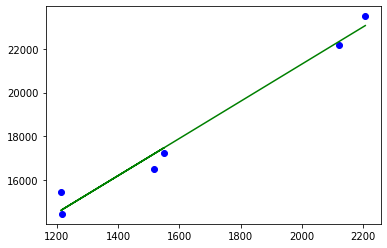

In [7]:
plt.plot(x, y, 'bo')
plt.plot(x, b0+b1*x, '-g')
plt.show()

In [8]:
R = rho**2
print(R)

0.9778142064515715


c) Il coefficiente di determinazione è molto prossimo a 1 per cui il mio modello è affidabile

In [9]:
#d)
x = np.array([1213, 1518, 1550, 1215, 2120, 2207, 3050, 850, 2175, 1128])
y = np.array([15474, 16497, 17224, 14459, 22186, 23483, 29349, 11314, 24095, 13982])
print(x, y)

[1213 1518 1550 1215 2120 2207 3050  850 2175 1128] [15474 16497 17224 14459 22186 23483 29349 11314 24095 13982]


In [10]:
n = np.size(x)
#calcolo la media dei dati
#xn = np.sum(x)/n
xn = np.mean(x)
yn = np.sum(y)/n
print(xn, yn)

1702.6 18806.3


In [11]:
xn2 = np.sum(x**2)/n
yn2 = np.sum(y**2)/n
xyn = np.sum(x*y)/n
#calcolo la varianza
sx = xn2-xn**2
sy = yn2-yn**2
#calcolo la covarianza
print(np.cov(x,y, bias = True))
sxy = xyn - xn*yn
print(sx, sy, sxy)

[[  405920.84  3405220.12]
 [ 3405220.12 28966097.61]]
405920.8400000003 28966097.610000014 3405220.120000005


In [12]:
rho = sxy/np.sqrt(sx*sy)
print(rho)

0.9930692208128389


4523.397510164779 8.388877299327628


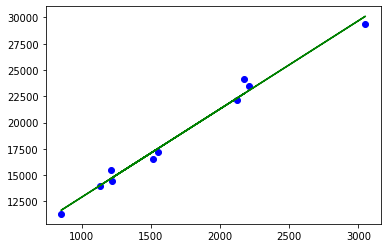

In [13]:
b1 = sxy/sx
b0 = yn-b1*xn
print(b0, b1)
plt.plot(x, y, 'bo')
plt.plot(x, b0+b1*x, '-g')
plt.show()

In [14]:
R = rho**2
print(R)

0.986186477325819


I nuovi dati mi hanno permesso di avere un modello più predittivo. Infatti la retta che ho trovato è in accordo con dati che variano su un range maggiore. Noto inoltre che, anche se impercettibilmente, sia la correlazione che il coefficiente di determinazione sono migliorati.


# La vendemmia -- 23-10-25

In [15]:
A = np.array(np.arange(2, 14))
G = np.array([1, 1, 10, 31, 53, 92, 124, 90, 61, 20, 16, 1])
N = np.sum(G)

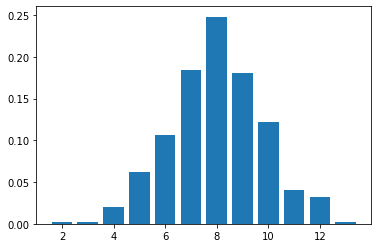

In [16]:
#a)
plt.bar(A, G/N)
plt.show()

In [17]:
#b)
m = np.sum(A*G)/N
print(m)
v = np.sum(G*(A-m)**2)/(N-1)
print(v)

7.998
3.2044048096192386


In [25]:
#c)
alpha = 0.05
e = np.sqrt(v)*t.ppf(1-0.5*alpha, N)/np.sqrt(N)
print('[', m - e, m+e, ']')

[ 7.840714272493259 8.15528572750674 ]


L'istogramma ricorda una distribuzione normale. Posso provare a graficarne una che abbia come parametri di media e varianza quelli che ho stimato dai dati misurati!_

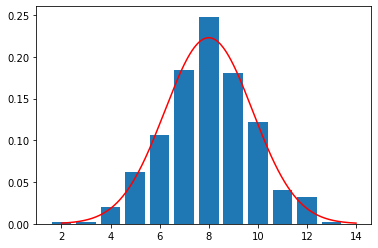

In [19]:
k = np.linspace(2, 14, 500)
plt.bar(A, G/N)
plt.plot(k, norm.pdf(k, m, np.sqrt(v)),  "r")
plt.show()

# Gioco dell'oca -- 17-06-25

a) La variabile lancio del dado segue una distribuzione multinomiale di parametri n = 1, m = 6, p = 1/6

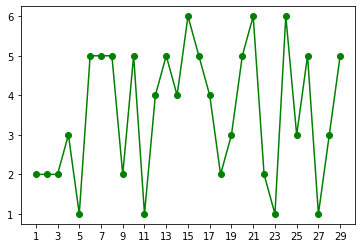

In [5]:
#b) Simulo una partita
N = 100
#Genero N lanci (perché al più posso fare 100 lanci da 1)
dado = np.random.randint(1, 7, N)
#Vedo quando finisce la partita
dado_sum = np.cumsum(dado)
#Cerco l'indice di partita finita
index = np.argmax(dado_sum >= N)
#Creo un vettore che contiene solo i lanci della partita
dado_partita= dado[:index+1]
#Faccio il plot
#N.B. Non aveva alcun senso fare un istogramma come plot
#Non stiamo plottando valori e frequenze ma i risultati a ogni lancio
x = np.arange(index+1)
plt.xticks(np.arange(1, index+2, 2))
plt.plot(x+1, dado_partita, '-og')
plt.show()

In [3]:
#c) Genero N=100 partite - nota che genero una matrice di numeri
dado = np.random.randint(1, 7, size=(N, N))
#Ripeto quanto fatto sopra per ogni partita usando axis
dado_sum = np.cumsum(dado, axis=1)
#Creo il vettore con gli indici + 1 che dicono quando finisce la partita
tempi = np.argmax(dado_sum>= N, axis=1)+1

In [6]:
#d) Calcolo la media
m_tempi = np.sum(tempi)/N
print(m_tempi)

29.04
